In [1]:
import pandas as pd
import numpy as np


In [2]:
data = pd.read_csv("house_rentals.csv")
data.shape

(17890, 17)

In [4]:
data.head()

,url,listing_type,name,price,category,bedrooms,bathrooms,floor_area,location,condition,amenities,region,locality,parking_space,is_furnished,lat,lng
0,https://tonaton.com/a-MfYFNdCgCTytOcmvZIh0Kzrj...,rentals,"2bdrm Apartment in Charclem Ventures, East Leg...",9196,Flats,2.0,2.0,145.0,"Greater Accra, East Legon",Used,"24-hour Electricity,Air Conditioning,Balcony,C...",Greater Accra,East Legon,False,Semi-Furnished,5.635828,-0.161359
1,https://tonaton.com/a-MfYFNdCgwtb8Itol9odpMPvC...,rentals,"2bdrm Apartment in , Dzorwulu for rent",7500,Flats,2.0,2.0,100.0,"Greater Accra, Dzorwulu",Used,"24-hour Electricity,Air Conditioning,Apartment...",Greater Accra,Dzorwulu,False,Unfurnished,5.614123,-0.195647
2,https://tonaton.com/a-MfYFNdCgPjnzPYwNFEv5JrGy...,rentals,"4bdrm House in Lakeside Estate, for Rent",11200,Detached,4.0,5.0,100.0,"Greater Accra, Ashaley Botwe, Lake Side Estate",New,"Tiled Floor,Chandelier,Dining Area,Balcony,Pop...",Greater Accra,Ashaley Botwe,False,Semi-Furnished,5.680213,-0.137248
3,https://tonaton.com/a-MfYFNdCgwmXHQRNJiSR3rok8...,rentals,"3bdrm House in Ayathar Bedroom, Teshie for Rent",2500,Detached,3.0,3.0,17.0,"Greater Accra, Teshie",Used,"Pop Ceiling,Pre-Paid Meter,24-hour Electricity...",Greater Accra,Teshie,False,Semi-Furnished,5.583166,-0.104608
4,https://tonaton.com/a-MfYFNdCgn3Bcs511lKnFE19i...,rentals,"3bdrm House in Manet Viile Estate, Spintex for...",9146,Detached,3.0,3.0,160.0,"Greater Accra, Spintex",Used,"Pre-Paid Meter,Dining Area,Chandelier,Balcony,...",Greater Accra,Spintex,False,Semi-Furnished,5.637614,-0.126606


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17890 entries, 0 to 17889
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   url            17890 non-null  object 
 1   listing_type   17890 non-null  object 
 2   name           17890 non-null  object 
 3   price          17890 non-null  int64  
 4   category       17890 non-null  object 
 5   bedrooms       17890 non-null  float64
 6   bathrooms      17890 non-null  float64
 7   floor_area     17890 non-null  float64
 8   location       17890 non-null  object 
 9   condition      17890 non-null  object 
 10  amenities      17890 non-null  object 
 11  region         17890 non-null  object 
 12  locality       17890 non-null  object 
 13  parking_space  17890 non-null  bool   
 14  is_furnished   17890 non-null  object 
 15  lat            17890 non-null  float64
 16  lng            17890 non-null  float64
dtypes: bool(1), float64(5), int64(1), object(10)
memor

In [7]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
price,17890.0,7999.412968,10404.773528,416.000000,1700.000000,3500.000000,9872.250000,59524.000000
bedrooms,17890.0,2.458580,1.262908,1.000000,2.000000,2.000000,3.000000,20.000000
bathrooms,17890.0,2.564561,1.377651,1.000000,1.000000,2.000000,3.000000,20.000000
floor_area,17890.0,556.094913,1044.912578,10.000000,100.000000,145.000000,600.000000,5000.000000
lat,17890.0,5.725901,0.454570,4.849041,5.593759,5.637614,5.682581,9.410999
lng,17890.0,-0.246623,0.322523,-2.579248,-0.215087,-0.161359,-0.135459,0.563609


In [8]:
df = data.copy()

df = df.drop(columns=['url', 'name', 'listing_type', 'parking_space', 'lat', 'lng', 'location', 'region'])

df['amenities_count'] = df['amenities'].fillna('').apply(lambda x: len([a for a in x.split(',') if a.strip() != '']))
df = df.drop(columns=['amenities'])

df.shape

(17890, 9)

In [9]:
df = df[df.bedrooms <= 10]
df = df[df.bathrooms <= 10]
df = df[df.price <= 50000]
df.shape

(17730, 9)

In [12]:
data.head()

,url,listing_type,name,price,category,bedrooms,bathrooms,floor_area,location,condition,amenities,region,locality,parking_space,is_furnished,lat,lng
0,https://tonaton.com/a-MfYFNdCgCTytOcmvZIh0Kzrj...,rentals,"2bdrm Apartment in Charclem Ventures, East Leg...",9196,Flats,2.0,2.0,145.0,"Greater Accra, East Legon",Used,"24-hour Electricity,Air Conditioning,Balcony,C...",Greater Accra,East Legon,False,Semi-Furnished,5.635828,-0.161359
1,https://tonaton.com/a-MfYFNdCgwtb8Itol9odpMPvC...,rentals,"2bdrm Apartment in , Dzorwulu for rent",7500,Flats,2.0,2.0,100.0,"Greater Accra, Dzorwulu",Used,"24-hour Electricity,Air Conditioning,Apartment...",Greater Accra,Dzorwulu,False,Unfurnished,5.614123,-0.195647
2,https://tonaton.com/a-MfYFNdCgPjnzPYwNFEv5JrGy...,rentals,"4bdrm House in Lakeside Estate, for Rent",11200,Detached,4.0,5.0,100.0,"Greater Accra, Ashaley Botwe, Lake Side Estate",New,"Tiled Floor,Chandelier,Dining Area,Balcony,Pop...",Greater Accra,Ashaley Botwe,False,Semi-Furnished,5.680213,-0.137248
3,https://tonaton.com/a-MfYFNdCgwmXHQRNJiSR3rok8...,rentals,"3bdrm House in Ayathar Bedroom, Teshie for Rent",2500,Detached,3.0,3.0,17.0,"Greater Accra, Teshie",Used,"Pop Ceiling,Pre-Paid Meter,24-hour Electricity...",Greater Accra,Teshie,False,Semi-Furnished,5.583166,-0.104608
4,https://tonaton.com/a-MfYFNdCgn3Bcs511lKnFE19i...,rentals,"3bdrm House in Manet Viile Estate, Spintex for...",9146,Detached,3.0,3.0,160.0,"Greater Accra, Spintex",Used,"Pre-Paid Meter,Dining Area,Chandelier,Balcony,...",Greater Accra,Spintex,False,Semi-Furnished,5.637614,-0.126606


In [13]:
locality_counts = df.locality.value_counts()

def group_locality(locality):
    if locality_counts[locality] >= 30:
        return locality
    else:
        return 'Other'

df['locality_grouped'] = df.locality.apply(group_locality)
df = df.drop(columns=['locality'])

In [15]:
df['log_price'] = np.log(df.price)

Skew of raw price: 2.1618110111607525
Skew of log price: 0.2757611948664681


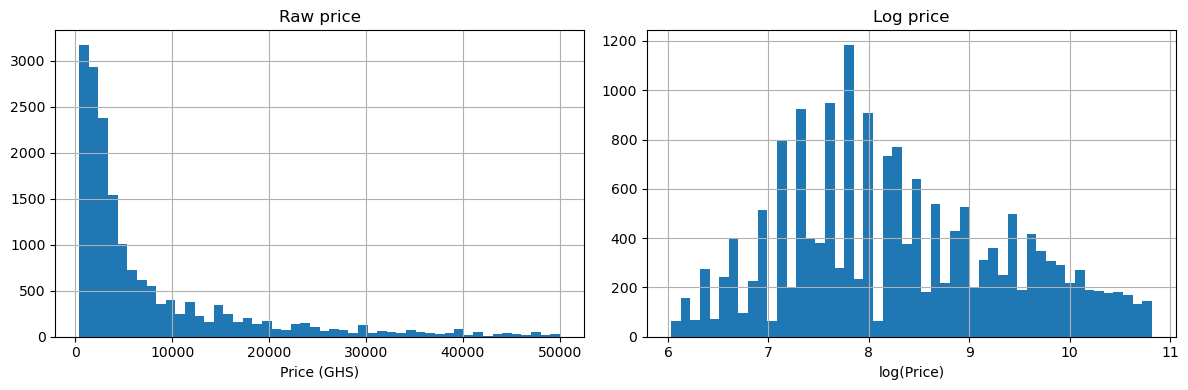

In [16]:
import matplotlib.pyplot as plt

print("Skew of raw price:", df.price.skew())
print("Skew of log price:", df.log_price.skew())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df.price.hist(bins=50, ax=axes[0])
axes[0].set_title("Raw price")
axes[0].set_xlabel("Price (GHS)")

df.log_price.hist(bins=50, ax=axes[1])
axes[1].set_title("Log price")
axes[1].set_xlabel("log(Price)")

plt.tight_layout()
plt.show()

In [17]:
df.groupby('is_furnished')['price'].mean()

is_furnished
Furnished         17493.547957
Semi-Furnished     7489.530499
Unfurnished        5475.388194
Name: price, dtype: float64

In [19]:
df_encoded = pd.get_dummies(df, columns=['category', 'condition', 'is_furnished', 'locality_grouped'], drop_first=True)

X = df_encoded.drop(columns=['price', 'log_price'])
y = df_encoded['log_price']

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((14184, 66), (3546, 66))

In [22]:
numeric_cols = ['bedrooms', 'bathrooms', 'floor_area', 'amenities_count']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

In [23]:
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

linear_predictions = linear_model.predict(X_test_scaled)

In [24]:
print(linear_model.coef_[:5])  
print(linear_model.intercept_)

print(linear_predictions[:5])   
print(y_test[:5].values)        

[ 0.32777883  0.20177595 -0.067578    0.20885327 -0.06066222]
9.746435852620632
[ 8.93165754  7.98242747 10.55918959  8.67513831  7.50106295]
[9.54987933 8.29404964 9.90348755 9.45720045 7.49554194]


In [25]:
random_forest_model = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)
random_forest_model.fit(X_train_scaled, y_train)

random_forest_predictions = random_forest_model.predict(X_test_scaled)

In [26]:
models_results = [
    ('Linear Regression', linear_predictions),
    ('Random Forest', random_forest_predictions)
]

for model_name, predictions in models_results:
    r2_log_scale = r2_score(y_test, predictions)
    
    actual_price = np.exp(y_test)
    predicted_price = np.exp(predictions)
    
    r2_price_scale = r2_score(actual_price, predicted_price)
    rmse_price = np.sqrt(mean_squared_error(actual_price, predicted_price))
    mae_price = mean_absolute_error(actual_price, predicted_price)
    
    print(f"--- {model_name} ---")
    print(f"R2 (log scale):    {r2_log_scale:.3f}")
    print(f"R2 (price scale):  {r2_price_scale:.3f}")
    print(f"RMSE (GHS):        {rmse_price:,.0f}")
    print(f"MAE (GHS):         {mae_price:,.0f}")
    print()

--- Linear Regression ---
R2 (log scale):    0.767
R2 (price scale):  0.347
RMSE (GHS):        7,756
MAE (GHS):         3,545

--- Random Forest ---
R2 (log scale):    0.764
R2 (price scale):  0.603
RMSE (GHS):        6,050
MAE (GHS):         3,192



In [27]:
import pickle

In [28]:
filename = 'trained_model.sav'

In [31]:
pickle.dump(random_forest_model, open(filename, 'wb'))

In [32]:
loaded_model = pickle.load(open('trained_model.sav', 'rb'))

In [35]:
feature_cols = list(X.columns)
print(len(feature_cols))
print(feature_cols[:10])
print(scaler)

66
['bedrooms', 'bathrooms', 'floor_area', 'amenities_count', 'category_Duplex', 'category_Flats', 'category_Mansion', 'category_Semi-Detached', 'category_Townhouse', 'condition_Renovated']
StandardScaler()


In [36]:
new_listing = {
    'bedrooms': 2,
    'bathrooms': 2,
    'floor_area': 145,
    'amenities_count': 8,
    'category': 'Flats',
    'condition': 'New',
    'is_furnished': 'Furnished',
    'locality_grouped': 'East Legon'
}

In [37]:
# start with a row of all zeros, with the same 66 columns the model was trained on
input_df = pd.DataFrame([[0]*len(feature_cols)], columns=feature_cols)

# fill in the numeric values directly
input_df['bedrooms'] = new_listing['bedrooms']
input_df['bathrooms'] = new_listing['bathrooms']
input_df['floor_area'] = new_listing['floor_area']
input_df['amenities_count'] = new_listing['amenities_count']

# set the correct dummy column to 1 for each categorical choice
category_col = 'category_' + new_listing['category']
if category_col in input_df.columns:
    input_df[category_col] = 1

condition_col = 'condition_' + new_listing['condition']
if condition_col in input_df.columns:
    input_df[condition_col] = 1

furnished_col = 'is_furnished_' + new_listing['is_furnished']
if furnished_col in input_df.columns:
    input_df[furnished_col] = 1

locality_col = 'locality_grouped_' + new_listing['locality_grouped']
if locality_col in input_df.columns:
    input_df[locality_col] = 1

input_df

,bedrooms,bathrooms,floor_area,amenities_count,category_Duplex,category_Flats,category_Mansion,category_Semi-Detached,category_Townhouse,condition_Renovated,...,locality_grouped_Spintex,locality_grouped_Taifa-Burkina,locality_grouped_Takoradi,locality_grouped_Tamale Municipal,locality_grouped_Tantra Hills,locality_grouped_Tema Metropolitan,locality_grouped_Tesano,locality_grouped_Teshie,locality_grouped_Weija,locality_grouped_West Legon
0,2,2,145,8,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [38]:
scaler_filename = 'scaler.sav'
pickle.dump(scaler, open(scaler_filename, 'wb'))
print("Scaler saved!")

Scaler saved!


In [39]:
print(feature_cols)

['bedrooms', 'bathrooms', 'floor_area', 'amenities_count', 'category_Duplex', 'category_Flats', 'category_Mansion', 'category_Semi-Detached', 'category_Townhouse', 'condition_Renovated', 'condition_Used', 'is_furnished_Semi-Furnished', 'is_furnished_Unfurnished', 'locality_grouped_Ablekuma', 'locality_grouped_Abokobi', 'locality_grouped_Accra Metropolitan', 'locality_grouped_Achimota', 'locality_grouped_Adenta', 'locality_grouped_Adjiriganor', 'locality_grouped_Agbogba', 'locality_grouped_Airport Residential Area', 'locality_grouped_Ashaiman Municipal', 'locality_grouped_Ashaley Botwe', 'locality_grouped_Ashomang Estate', 'locality_grouped_Atwima Nwabiagya', 'locality_grouped_Awoshie', 'locality_grouped_Awutu Senya East Municipal', 'locality_grouped_Cantonments', 'locality_grouped_Dansoman', 'locality_grouped_Dome', 'locality_grouped_Dzorwulu', 'locality_grouped_East Legon', 'locality_grouped_Ga East Municipal', 'locality_grouped_Ga South Municipal', 'locality_grouped_Ga West Municipal

In [40]:
print(sorted(df.locality_grouped.unique()))

['Abelemkpe', 'Ablekuma', 'Abokobi', 'Accra Metropolitan', 'Achimota', 'Adenta', 'Adjiriganor', 'Agbogba', 'Airport Residential Area', 'Ashaiman Municipal', 'Ashaley Botwe', 'Ashomang Estate', 'Atwima Nwabiagya', 'Awoshie', 'Awutu Senya East Municipal', 'Cantonments', 'Dansoman', 'Dome', 'Dzorwulu', 'East Legon', 'Ga East Municipal', 'Ga South Municipal', 'Ga West Municipal', 'Gbawe', 'Haatso', 'Kaneshie', 'Kasoa', 'Kumasi Metropolitan', 'Labadi', 'Labone', 'Lapaz', 'Ledzokuku-Krowor', 'Madina', 'New-Juaben Municipal', 'North Legon', 'Nungua', 'Ofankor', 'Old Ashomang', 'Osu', 'Other', 'Oyarifa', 'Oyibi', 'Pokuase', 'Sowutwuom', 'Spintex', 'Taifa-Burkina', 'Takoradi', 'Tamale Municipal', 'Tantra Hills', 'Tema Metropolitan', 'Tesano', 'Teshie', 'Weija', 'West Legon']
